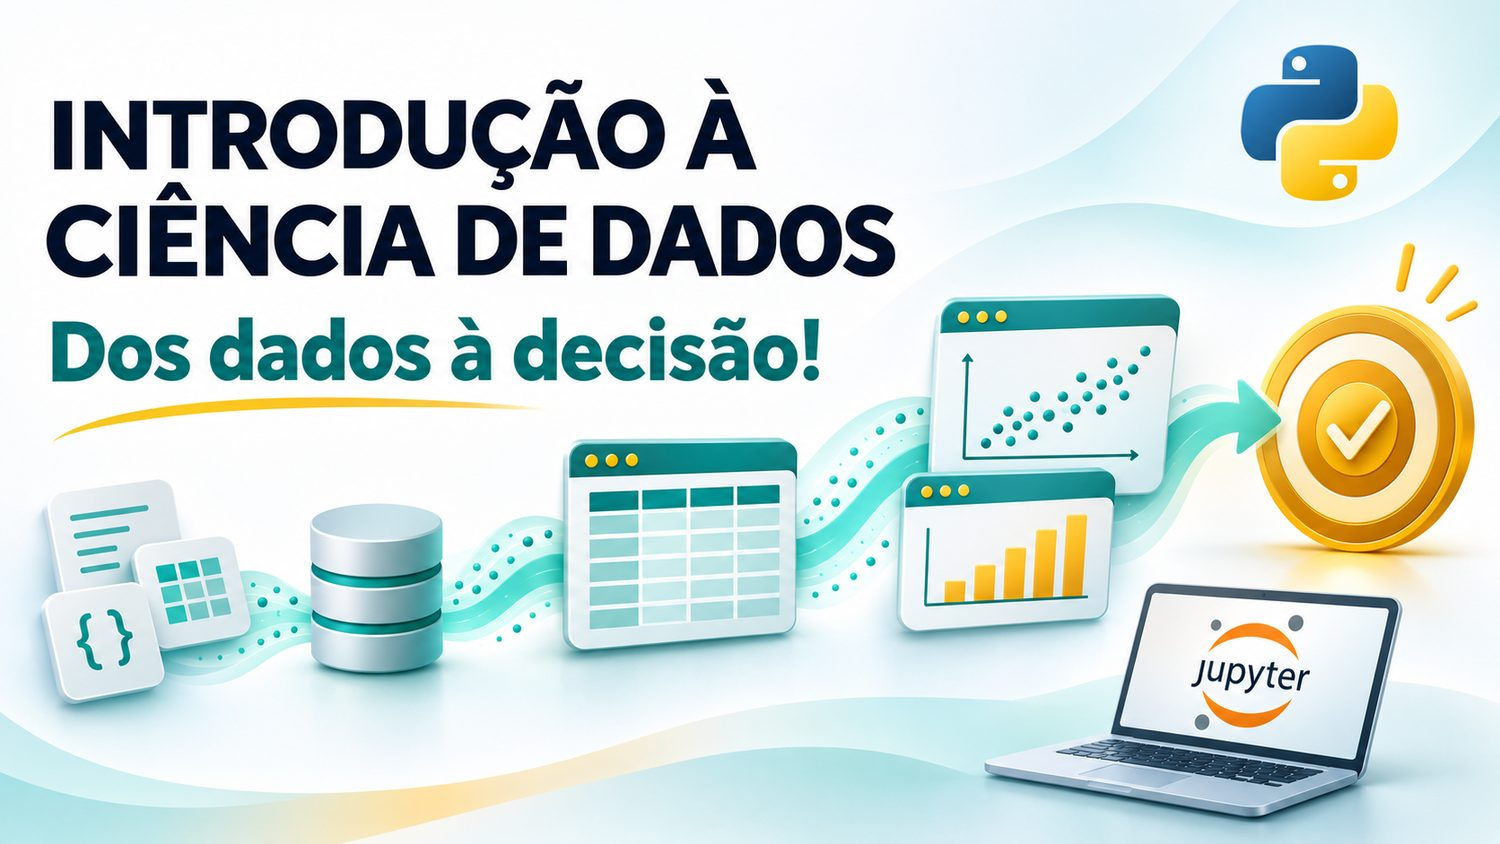

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_3_explorar_os_dados/04_Visualizacao.ipynb)

# Capítulo 4 – Visualização

Um gráfico é a forma mais rápida de ver o que uma tabela esconde, e também a forma mais rápida de enganar, a quem o lê e a quem o faz. Este capítulo ensina a escolher o gráfico pela pergunta, a evitar as decisões que distorcem e a transformar um rascunho num gráfico que se percebe sem explicação.

> **Objetivos:** explicar porque um resumo numérico não substitui um gráfico; escolher o tipo de gráfico adequado a cada pergunta; escolher o número de classes de um histograma; reconhecer eixos truncados, eixos duplos e outras decisões que enganam; melhorar um gráfico com título, rótulos diretos e destaque; usar pequenos múltiplos.

**Pré-requisitos:** capítulos 1 a 3 deste módulo. A sintaxe do matplotlib está em [Visualização de dados](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_1_introducao/24_Visualizacao_Dados.ipynb) e na ficha [Consulta rápida de visualização](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/consulta_rapida/Consulta_Rapida_Visualizacao.pdf).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_escolas(semente=11):
    """Gera o consumo diário de eletricidade de 30 escolas fictícias durante um ano letivo (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    n = 30
    tipo = rng.choice(["básica", "secundária"], n, p=[0.6, 0.4])
    alunos = np.where(tipo == "básica", rng.integers(120, 520, n), rng.integers(450, 1400, n))
    escolas = pd.DataFrame({
        "escola_id": [f"E{i:02d}" for i in range(1, n + 1)],
        "tipo": tipo,
        "alunos": alunos,
        "area_m2": (alunos * rng.normal(9.0, 1.2, n)).round(-1).astype(int),
        "ano_construcao": rng.integers(1965, 2016, n),
        "paineis_solares": rng.random(n) < 0.3})
    dias = pd.date_range("2025-09-01", "2026-08-31", freq="D")
    dia_do_ano = dias.dayofyear.to_numpy()
    temperatura = 16.5 + 7.5 * np.cos(2 * np.pi * (dia_do_ano - 205) / 365) + rng.normal(0, 2.2, len(dias))
    ferias = (((dias >= "2025-12-20") & (dias <= "2026-01-04")) | ((dias >= "2026-03-28") & (dias <= "2026-04-12"))
              | (dias >= "2026-07-01"))
    meteo = pd.DataFrame({"data": dias, "temperatura": temperatura.round(1), "ferias": ferias})
    tabelas = []
    for e in escolas.itertuples():
        base = 0.55 * e.alunos + 0.012 * e.area_m2 * (1.25 if e.ano_construcao < 1990 else 1.0)
        aquecimento = 1 + 0.045 * np.clip(15 - temperatura, 0, None)
        ocupacao = np.where(dias.dayofweek >= 5, 0.22, 1.0) * np.where(ferias, 0.30, 1.0)
        sol = np.clip(0.5 + 0.5 * np.cos(2 * np.pi * (dia_do_ano - 172) / 365), 0, 1)
        solar = 1 - (0.28 * sol if e.paineis_solares else 0)
        kwh = base * aquecimento * np.maximum(ocupacao, 0.08) * solar * rng.lognormal(0, 0.10, len(dias))
        avarias = rng.random(len(dias)) < 0.004                     # dias com um consumo anormal
        kwh = np.where(avarias, kwh * rng.uniform(2.5, 4.0, len(dias)), kwh)
        tabelas.append(pd.DataFrame({"escola_id": e.escola_id, "data": dias, "kwh": kwh.round(1)}))
    return escolas, pd.concat(tabelas, ignore_index=True), meteo


escolas, consumo, meteo = gerar_escolas()
consumo.head()

,escola_id,data,kwh
0,E01,2025-09-01,300.5
1,E01,2025-09-02,264.6
2,E01,2025-09-03,265.0
3,E01,2025-09-04,270.0
4,E01,2025-09-05,303.9


In [3]:
dados = consumo.merge(meteo, on="data").merge(escolas, on="escola_id")
dados["kwh_por_aluno"] = dados["kwh"] / dados["alunos"]
aulas = dados[(dados["data"].dt.dayofweek < 5) & ~dados["ferias"]]

## O mesmo resumo, quatro histórias

As quatro nuvens de pontos seguintes foram construídas para terem exatamente as mesmas médias, os mesmos desvios padrão e a mesma correlação.

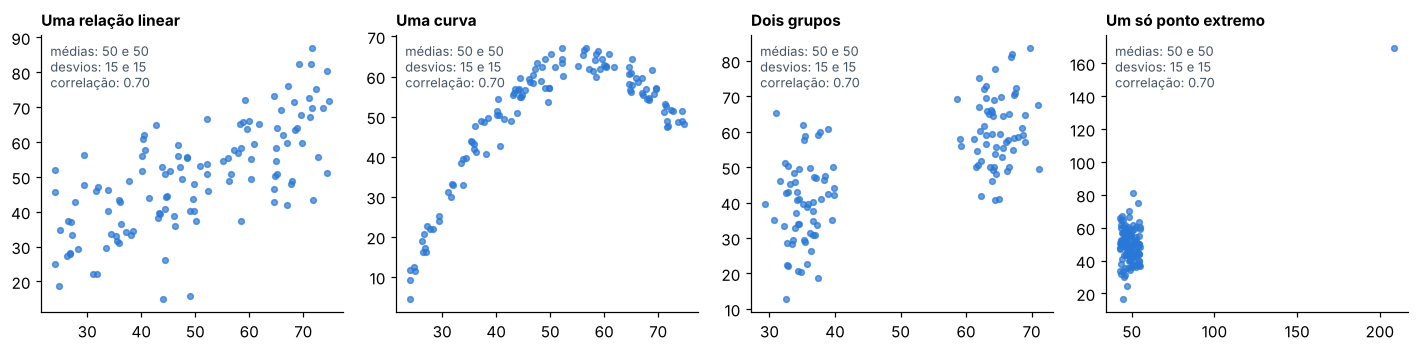

In [4]:
def com_as_mesmas_medidas(x, y, r=0.7):
    """Ajusta y para que x e y fiquem com média 50, desvio padrão 15 e correlação r, mantendo a forma geral."""
    zx = (x - x.mean()) / x.std()
    residuo = y - np.polyval(np.polyfit(zx, y, 1), zx)          # a parte de y que não é explicada por uma reta
    residuo = (residuo - residuo.mean()) / residuo.std()
    zy = r * zx + np.sqrt(1 - r ** 2) * residuo
    return 50 + 15 * zx, 50 + 15 * zy


rng = np.random.default_rng(5)
n = 120
x = rng.uniform(0, 1, n)
agrupado = np.repeat([0.2, 0.8], n // 2) + rng.normal(0, 0.05, n)
com_extremo = np.append(rng.uniform(0.3, 0.5, n - 1), 3.0)
formas = [("Uma relação linear", x, x + rng.normal(0, 0.2, n)),
          ("Uma curva", x, -(x - 0.75) ** 2 + rng.normal(0, 0.02, n)),
          ("Dois grupos", agrupado, agrupado + rng.normal(0, 0.12, n)),
          ("Um só ponto extremo", com_extremo, np.append(rng.normal(0, 1, n - 1), 9.0))]

fig, eixos = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, (titulo, a, b) in zip(eixos, formas):
    px, py = com_as_mesmas_medidas(a, b)
    ax.scatter(px, py, s=14, color=AZUL, alpha=0.7)
    ax.set_title(titulo, fontsize=10)
    ax.text(0.03, 0.97, f"médias: {px.mean():.0f} e {py.mean():.0f}\ndesvios: {px.std():.0f} e {py.std():.0f}\ncorrelação: {np.corrcoef(px, py)[0, 1]:.2f}",
            transform=ax.transAxes, va="top", fontsize=8.5, color="#465463")
plt.tight_layout()
plt.show()

Quem só visse a tabela de medidas diria que os quatro conjuntos são iguais. Não são: um tem uma relação linear, outro uma curva, outro dois grupos separados, e no último a correlação inteira deve-se a um único ponto.

> **Desenha sempre os dados antes de os resumir.** As medidas do capítulo 3 descrevem bem uma nuvem de pontos «bem-comportada» e mal todas as outras.

## Escolher o gráfico pela pergunta

Não se começa por «que gráfico fica bem?». Começa-se por «o que quero saber?».

| A pergunta é sobre… | Exemplo | Gráfico | Evitar |
| --- | --- | --- | --- |
| **Distribuição** de uma variável | Como se distribui o consumo diário? | Histograma, diagrama de caixa | Uma barra com a média |
| **Comparação** entre grupos | Que escolas gastam mais por aluno? | Barras ordenadas | Gráfico circular |
| **Relação** entre duas variáveis numéricas | O consumo depende da temperatura? | Dispersão | Duas linhas em eixos diferentes |
| **Evolução** no tempo | Como muda o consumo ao longo do ano? | Linha | Barras com muitas categorias |
| **Duas categorias** e um valor | Consumo por escola e por mês | Mapa de calor | Barras em 3D |
| **Partes de um todo** | Que fração do consumo é ao fim de semana? | Barra empilhada, ou só o número | Gráfico circular com muitas fatias |

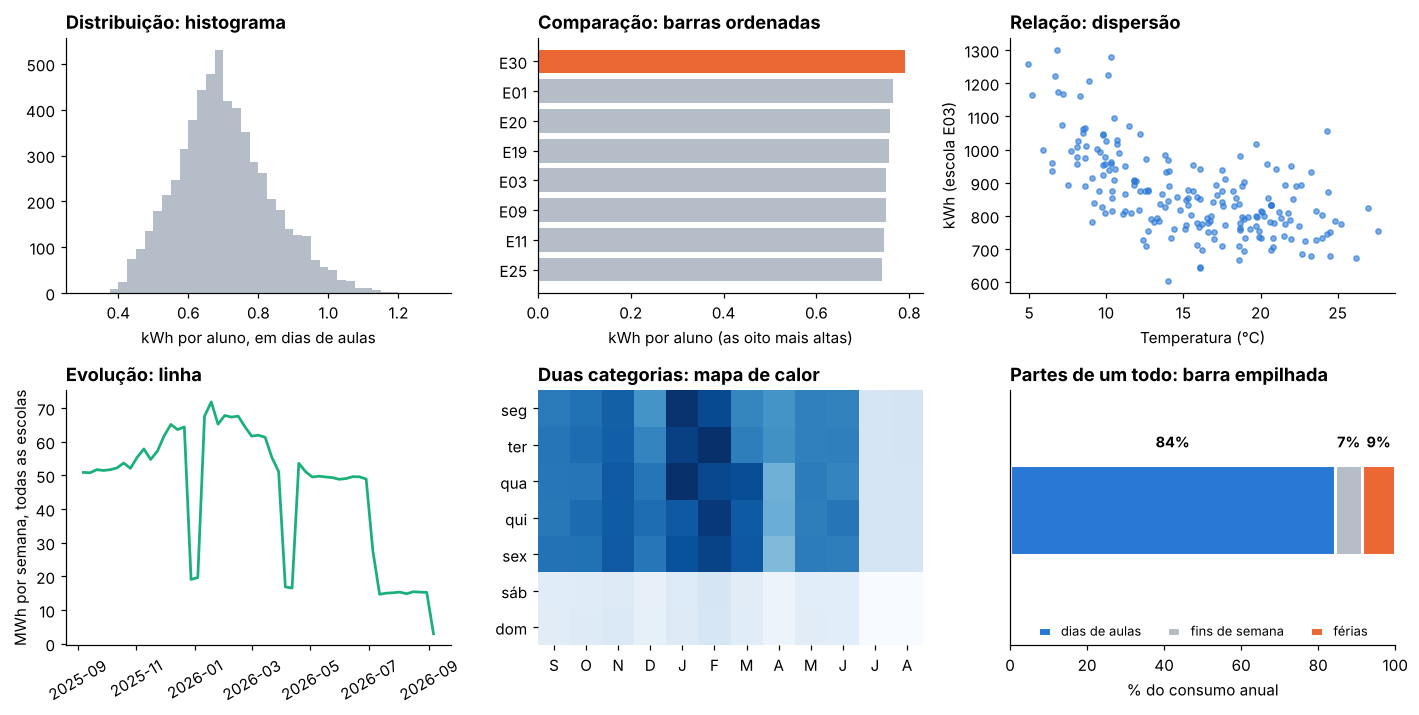

In [5]:
fig, eixos = plt.subplots(2, 3, figsize=(13, 6.6))

ax = eixos[0, 0]                                                    # distribuição
ax.hist(aulas["kwh_por_aluno"], bins=40, range=(0.3, 1.3), color=CINZA)
ax.set_title("Distribuição: histograma")
ax.set_xlabel("kWh por aluno, em dias de aulas")

ax = eixos[0, 1]                                                    # comparação
por_escola = aulas.groupby("escola_id")["kwh_por_aluno"].mean().sort_values().tail(8)
ax.barh(por_escola.index, por_escola, color=[CINZA] * 7 + [LARANJA])
ax.set_title("Comparação: barras ordenadas")
ax.set_xlabel("kWh por aluno (as oito mais altas)")

ax = eixos[0, 2]                                                    # relação
uma = aulas[aulas["escola_id"] == "E03"]
ax.scatter(uma["temperatura"], uma["kwh"], s=12, color=AZUL, alpha=0.6)
ax.set_title("Relação: dispersão")
ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("kWh (escola E03)")

ax = eixos[1, 0]                                                    # evolução
semanal = dados.groupby(pd.Grouper(key="data", freq="W"))["kwh"].sum() / 1000
ax.plot(semanal.index, semanal, color=VERDE, lw=1.8)
ax.set_title("Evolução: linha")
ax.set_ylabel("MWh por semana, todas as escolas")
ax.tick_params(axis="x", rotation=30)

ax = eixos[1, 1]                                                    # duas categorias
nomes = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
grelha = dados.pivot_table(index=dados["data"].dt.dayofweek, columns=dados["data"].dt.month, values="kwh", aggfunc="mean")
grelha = grelha[[9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]]
ax.imshow(grelha, cmap="Blues", aspect="auto")
ax.set_xticks(range(12), ["S", "O", "N", "D", "J", "F", "M", "A", "M", "J", "J", "A"])
ax.set_yticks(range(7), nomes)
ax.set_title("Duas categorias: mapa de calor")
ax.spines[:].set_visible(False)

ax = eixos[1, 2]                                                    # partes de um todo
fim_de_semana = dados["data"].dt.dayofweek >= 5
partes = [dados.loc[~fim_de_semana & ~dados["ferias"], "kwh"].sum(), dados.loc[fim_de_semana & ~dados["ferias"], "kwh"].sum(),
          dados.loc[dados["ferias"], "kwh"].sum()]
partes = np.array(partes) / sum(partes) * 100
esquerda = 0
for valor, rotulo, cor in zip(partes, ["dias de aulas", "fins de semana", "férias"], [AZUL, CINZA, LARANJA]):
    ax.barh([0], [valor], left=esquerda, color=cor, edgecolor="white", linewidth=2, height=0.6, label=rotulo)
    ax.text(esquerda + valor / 2, 0.42, f"{valor:.0f}%", ha="center", fontsize=9.5, fontweight="bold")
    esquerda += valor
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.02), fontsize=8.5, handlelength=1)
ax.set_title("Partes de um todo: barra empilhada")
ax.set_xlim(0, 100)
ax.set_ylim(-0.9, 0.8)
ax.set_yticks([])
ax.set_xlabel("% do consumo anual")

plt.tight_layout()
plt.show()

Seis perguntas, seis gráficos, os mesmos dados. Cada um mostra uma coisa que os outros não mostram: o histograma tem uma cauda; o gráfico de dispersão revela que o consumo sobe quando a temperatura desce abaixo de cerca de 15 °C; a linha tem as interrupções das férias; o mapa de calor mostra de uma vez o efeito do mês e o do dia da semana.

## O histograma depende das classes

Um histograma conta quantos valores caem em cada intervalo. O número de intervalos (as **classes**) é uma escolha, e muda o que se vê.

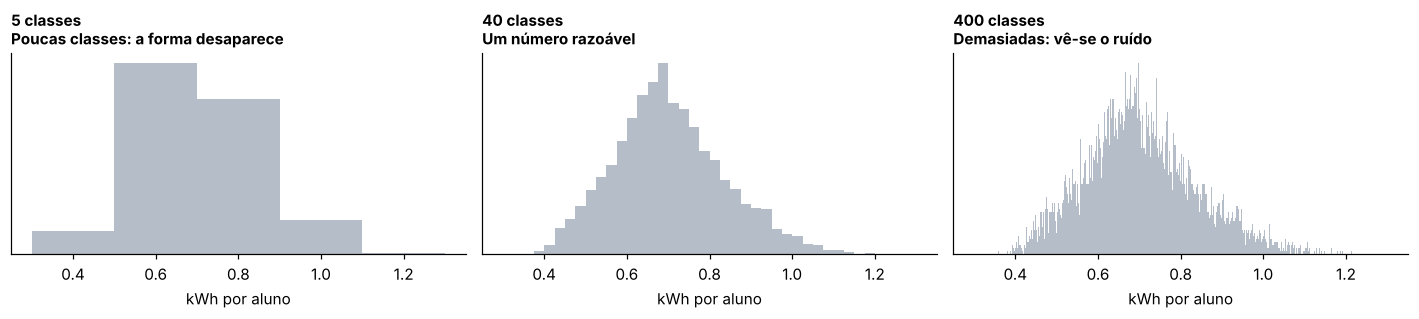

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3))
for ax, classes, comentario in zip(eixos, [5, 40, 400], ["Poucas classes: a forma desaparece", "Um número razoável", "Demasiadas: vê-se o ruído"]):
    ax.hist(aulas["kwh_por_aluno"], bins=classes, range=(0.3, 1.3), color=CINZA)
    ax.set_title(f"{classes} classes\n{comentario}", fontsize=10)
    ax.set_xlabel("kWh por aluno")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Não há um número certo. Experimenta dois ou três e escolhe o que mostra a forma sem mostrar o acaso. Um ponto de partida comum é a raiz quadrada do número de observações.

## Cinco decisões que enganam

### 1. O eixo que não começa em zero

Numa barra, o olho compara **comprimentos**. Se o eixo não começar em zero, os comprimentos deixam de ser proporcionais aos valores.

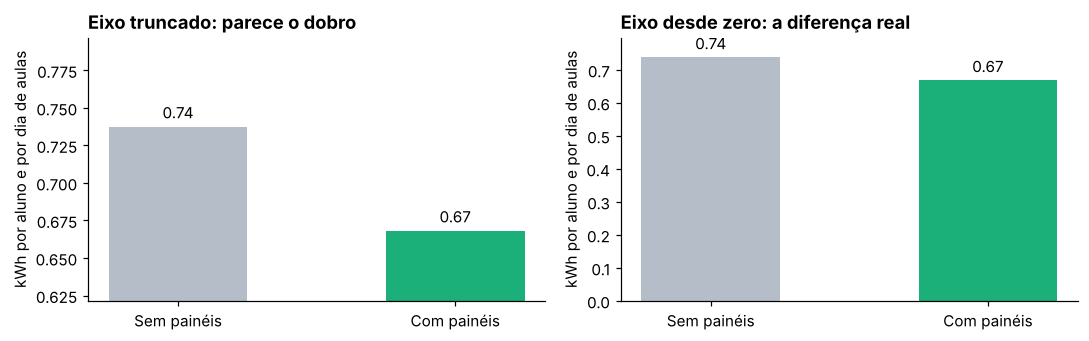

Diferença real: 9%


In [7]:
tipos = aulas.groupby("paineis_solares")["kwh_por_aluno"].mean()
valores = [tipos[False], tipos[True]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, titulo, base in [(ax1, "Eixo truncado: parece o dobro", min(valores) * 0.93), (ax2, "Eixo desde zero: a diferença real", 0)]:
    barras = ax.bar(["Sem painéis", "Com painéis"], valores, color=[CINZA, VERDE], width=0.5)
    ax.bar_label(barras, fmt="%.2f", padding=3)
    ax.set_ylim(base, max(valores) * 1.08)
    ax.set_title(titulo)
    ax.set_ylabel("kWh por aluno e por dia de aulas")
plt.tight_layout()
plt.show()

print(f"Diferença real: {(1 - valores[1] / valores[0]):.0%}")

Os dois gráficos têm os mesmos números. O da esquerda sugere uma diferença enorme; o da direita mostra a verdadeira.

A regra aplica-se às **barras**. Num gráfico de linhas ou de dispersão, o que se lê é a posição e a inclinação, e começar em zero pode esconder uma variação que interessa. Aí, o eixo ajusta-se aos dados e diz-se claramente a escala.

### 2. Dois eixos verticais

Pôr duas variáveis no mesmo gráfico, cada uma com o seu eixo, parece poupar espaço. O problema é que o ponto onde as linhas se cruzam e a distância entre elas dependem só das escalas escolhidas, e quem faz o gráfico pode fazê-las dizer o que quiser.

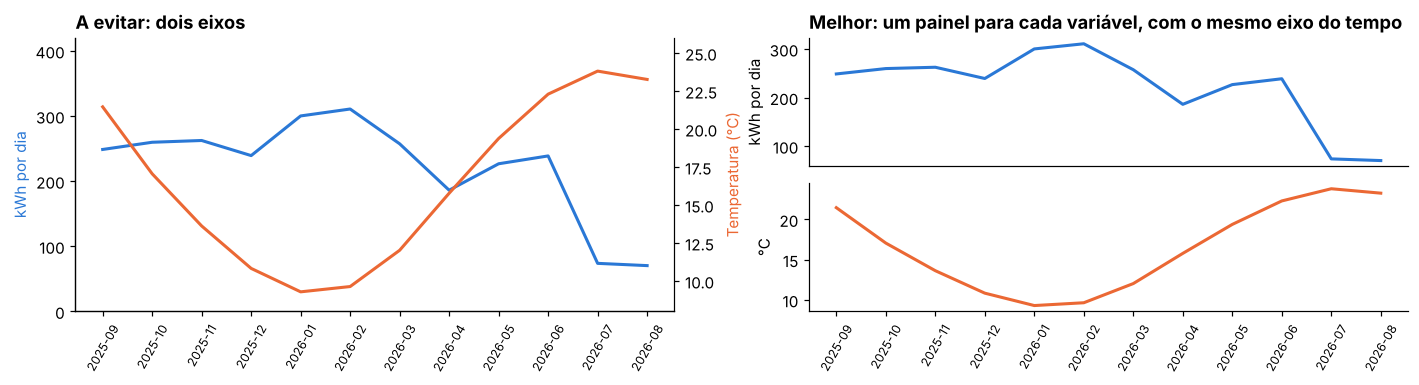

In [8]:
mensal = dados.groupby(dados["data"].dt.to_period("M")).agg(kwh=("kwh", "mean"), temperatura=("temperatura", "mean"))
meses = mensal.index.astype(str)

fig = plt.figure(figsize=(13, 3.6))
ax = fig.add_subplot(1, 2, 1)
ax.plot(meses, mensal["kwh"], color=AZUL, lw=2)
ax.set_ylabel("kWh por dia", color=AZUL)
ax.set_ylim(0, 420)
outro = ax.twinx()
outro.plot(meses, mensal["temperatura"], color=LARANJA, lw=2)
outro.set_ylabel("Temperatura (°C)", color=LARANJA)
outro.set_ylim(8, 26)
outro.spines["right"].set_visible(True)
ax.set_title("A evitar: dois eixos")
ax.tick_params(axis="x", rotation=60, labelsize=8)

ax1 = fig.add_subplot(2, 2, 2)
ax1.plot(meses, mensal["kwh"], color=AZUL, lw=2)
ax1.set_ylabel("kWh por dia")
ax1.set_xticks([])
ax1.set_title("Melhor: um painel para cada variável, com o mesmo eixo do tempo")
ax2 = fig.add_subplot(2, 2, 4)
ax2.plot(meses, mensal["temperatura"], color=LARANJA, lw=2)
ax2.set_ylabel("°C")
ax2.tick_params(axis="x", rotation=60, labelsize=8)
plt.tight_layout()
plt.show()

Para mostrar a **relação** entre as duas variáveis, o gráfico certo nem é este: é o de dispersão, com uma variável em cada eixo (capítulo 5).

### 3. O gráfico circular

Comparar ângulos é difícil; comparar comprimentos é fácil.

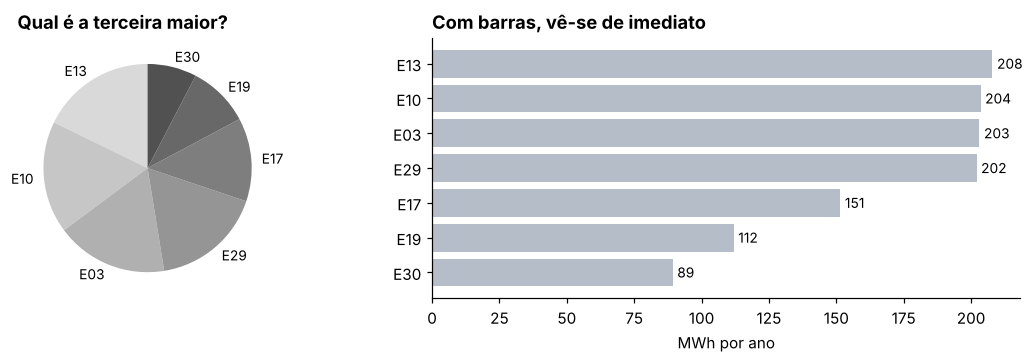

In [9]:
maiores = dados.groupby("escola_id")["kwh"].sum().sort_values(ascending=False).head(7)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
ax1.pie(maiores, labels=maiores.index, colors=plt.cm.Greys(np.linspace(0.25, 0.75, 7)), startangle=90, textprops={"fontsize": 9})
ax1.set_title("Qual é a terceira maior?")
barras = ax2.barh(maiores.index, maiores / 1000, color=CINZA)
ax2.bar_label(barras, fmt="%.0f", padding=3, fontsize=9)
ax2.invert_yaxis()
ax2.set_xlabel("MWh por ano")
ax2.set_title("Com barras, vê-se de imediato")
plt.tight_layout()
plt.show()

### 4. Categorias sem ordem

Barras por ordem alfabética obrigam o leitor a ordenar de cabeça. Ordena pelo valor, exceto quando as categorias têm uma ordem própria (meses, dias da semana, escalões).

### 5. Cor a mais

A cor serve para **destacar** ou para **distinguir**. Se cada barra tiver a sua cor sem que isso signifique alguma coisa, a cor só distrai. Regras simples: cinzento para o contexto e uma cor para o que interessa; a mesma cor para a mesma coisa em todos os gráficos; e nunca depender só da cor para transmitir informação, porque há quem não as distinga.

## Do rascunho ao gráfico final

O primeiro gráfico que se faz serve para **explorar**: é rápido e só tem de fazer sentido para quem o fez. O gráfico que se mostra a outra pessoa serve para **explicar**, e tem de se perceber sozinho.

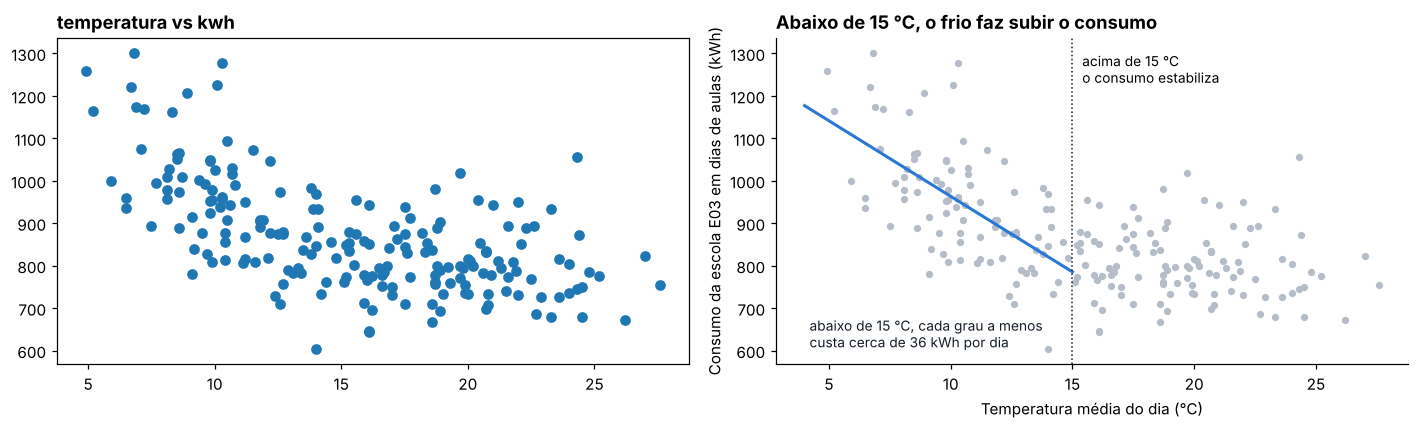

In [10]:
escola = aulas[aulas["escola_id"] == "E03"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.scatter(escola["temperatura"], escola["kwh"])                    # o rascunho, com as opções por omissão
ax1.set_title("temperatura vs kwh")
ax1.spines[["top", "right"]].set_visible(True)

ax2.scatter(escola["temperatura"], escola["kwh"], s=14, color=CINZA)
frios = escola[escola["temperatura"] < 15]
declive, ordenada = np.polyfit(frios["temperatura"], frios["kwh"], 1)
ax2.plot([4, 15], [declive * 4 + ordenada, declive * 15 + ordenada], color=AZUL, lw=2)
ax2.axvline(15, color=TINTA, ls=":", lw=1)
ax2.text(15.4, escola["kwh"].max(), "acima de 15 °C\no consumo estabiliza", fontsize=9, va="top")
ax2.text(4.2, escola["kwh"].min() + 5, f"abaixo de 15 °C, cada grau a menos\ncusta cerca de {-declive:.0f} kWh por dia", fontsize=9, color=TINTA)
ax2.set_xlabel("Temperatura média do dia (°C)")
ax2.set_ylabel("Consumo da escola E03 em dias de aulas (kWh)")
ax2.set_title("Abaixo de 15 °C, o frio faz subir o consumo")
plt.tight_layout()
plt.show()

O que mudou do rascunho para a versão final:

| Mudança | Porquê |
| --- | --- |
| O título passou a dizer a **conclusão** | «temperatura vs kwh» descreve os eixos; o leitor quer saber o que deve ver |
| Os eixos têm nome e **unidade** | Um número sem unidade é meio dado (módulo 2) |
| Os pontos passaram a cinzento | O contexto não deve competir com a mensagem |
| Uma só cor, na linha de tendência, e anotações junto aos dados | O leitor não precisa de ir a uma legenda e voltar |
| Uma linha resume a tendência, com o valor escrito | Dá ao leitor o número que ele ia tentar calcular |

## Pequenos múltiplos

Quando há muitos grupos, sobrepor todas as linhas no mesmo gráfico dá um novelo. A alternativa é repetir o mesmo gráfico pequeno, um por grupo, com **os mesmos eixos**.

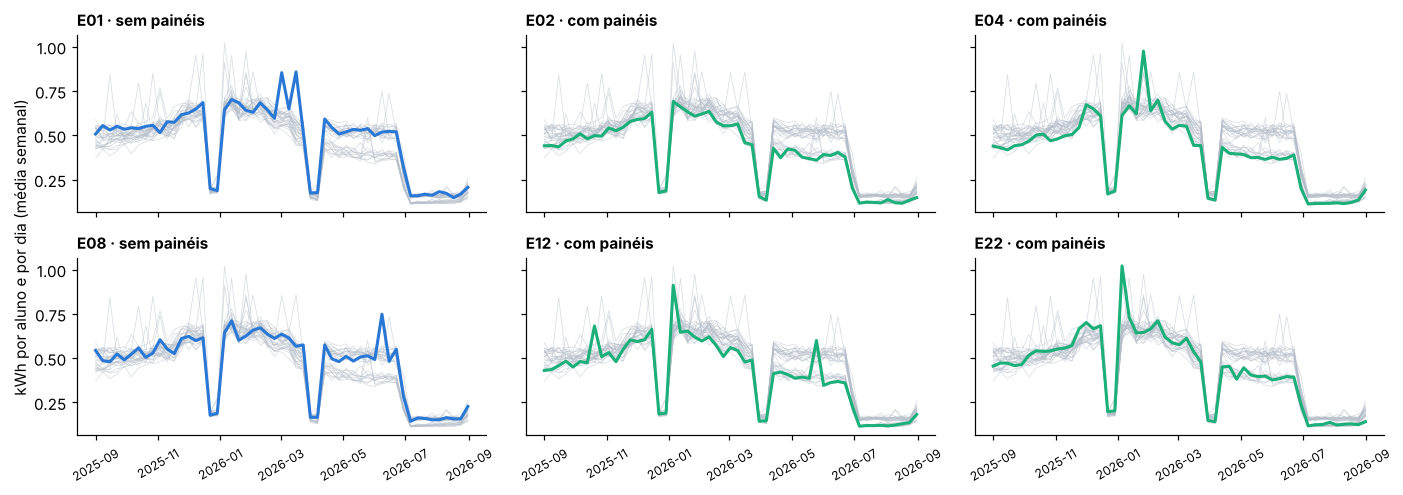

In [11]:
seis = ["E01", "E02", "E04", "E08", "E12", "E22"]
semanal = (dados.assign(semana=dados["data"].dt.to_period("W").dt.start_time)
           .groupby(["escola_id", "semana"])["kwh_por_aluno"].mean().unstack(0))

fig, eixos = plt.subplots(2, 3, figsize=(13, 4.6), sharex=True, sharey=True)
for ax, e in zip(eixos.ravel(), seis):
    ax.plot(semanal.index, semanal, color=CINZA, lw=0.5, alpha=0.5)        # todas as escolas, ao fundo
    paineis = bool(escolas.set_index("escola_id").loc[e, "paineis_solares"])
    ax.plot(semanal.index, semanal[e], color=VERDE if paineis else AZUL, lw=2)
    ax.set_title(f"{e} · {'com' if paineis else 'sem'} painéis", fontsize=10)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
fig.supylabel("kWh por aluno e por dia (média semanal)", fontsize=10)
plt.tight_layout()
plt.show()

Cada painel destaca uma escola sobre o fundo de todas as outras. Como os eixos são partilhados, comparam-se à vista: as escolas com painéis (a verde) descem mais na primavera do que as restantes.

## Uma lista de verificação

Antes de mostrares um gráfico a alguém:

1. O título diz o que o leitor deve concluir?
2. Os eixos têm nome e unidade?
3. O tipo de gráfico corresponde à pergunta?
4. Se há barras, o eixo começa em zero?
5. As categorias estão por uma ordem que faz sentido?
6. A cor está a destacar alguma coisa, ou só a enfeitar?
7. Percebe-se sem a legenda? Sem cor?
8. Há alguma coisa no gráfico que se possa tirar sem perder informação?

## Exercícios

### `Exercício 1` – Que gráfico?

Indica o gráfico mais adequado a cada pergunta:

1. Como evoluiu o número de alunos de uma escola nos últimos vinte anos?
2. As escolas mais antigas gastam mais por metro quadrado?
3. Como se distribuem as idades dos professores?
4. Que departamento teve mais despesa este ano, entre doze?
5. Em que horas do dia e dias da semana há mais entradas na biblioteca?

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Linha.
2. Dispersão (ano de construção contra consumo por metro quadrado).
3. Histograma ou diagrama de caixa.
4. Barras horizontais ordenadas.
5. Mapa de calor (hora × dia da semana).

</details>

### `Exercício 2` – Corrigir um gráfico

A célula seguinte desenha um gráfico com pelo menos cinco problemas. Identifica-os e refaz o gráfico.

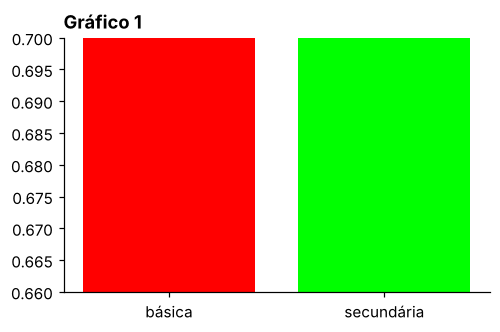

In [12]:
por_tipo = aulas.groupby("tipo")["kwh_por_aluno"].mean()
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(por_tipo.index, por_tipo, color=["red", "lime"])
ax.set_ylim(0.66, 0.70)
ax.set_title("Gráfico 1")
plt.show()
# Refaz o gráfico aqui

<details>
<summary><b>Ver uma solução possível</b></summary>

Problemas: o eixo não começa em zero e exagera uma diferença mínima; as cores não significam nada (e vermelho com verde é o par que mais pessoas confundem); o título não diz nada; o eixo vertical não tem nome nem unidade; os valores não estão escritos.

```python
fig, ax = plt.subplots(figsize=(5, 3))
barras = ax.bar(por_tipo.index, por_tipo, color=CINZA, width=0.5)
ax.bar_label(barras, fmt="%.3f", padding=3)
ax.set_ylim(0, por_tipo.max() * 1.15)
ax.set_ylabel("kWh por aluno e por dia de aulas")
ax.set_title("Básicas e secundárias gastam quase o mesmo por aluno")
plt.show()
```

</details>

### `Exercício 3` – Explorar com pequenos múltiplos

Desenha um gráfico de dispersão do consumo contra a temperatura para quatro escolas à tua escolha, em quatro painéis com eixos partilhados. Usa o consumo por aluno, para as escolas serem comparáveis. O padrão é o mesmo em todas?

In [13]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
fig, eixos = plt.subplots(1, 4, figsize=(13, 3), sharex=True, sharey=True)
for ax, e in zip(eixos, ["E01", "E02", "E05", "E13"]):
    t = aulas[aulas["escola_id"] == e]
    ax.scatter(t["temperatura"], t["kwh_por_aluno"].clip(upper=1.5), s=8, color=AZUL, alpha=0.5)
    ax.set_title(e)
    ax.set_xlabel("°C")
eixos[0].set_ylabel("kWh por aluno")
plt.tight_layout()
plt.show()
```

A forma é a mesma em todas: plana acima de cerca de 15 °C e a subir abaixo disso. O que muda é o nível e a inclinação, que dependem do edifício.

</details>

### `Exercício 4` – Do rascunho ao gráfico final

Faz um gráfico de linhas do consumo semanal total das escolas básicas e das secundárias. Depois melhora-o: título com a conclusão, unidades, rótulos junto às linhas em vez de legenda, e uma anotação a explicar as quebras.

In [14]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
t = dados.groupby([pd.Grouper(key="data", freq="W"), "tipo"])["kwh"].sum().unstack() / 1000
fig, ax = plt.subplots(figsize=(10, 3.4))
for tipo, cor in [("secundária", LARANJA), ("básica", AZUL)]:
    ax.plot(t.index, t[tipo], color=cor, lw=2)
    ax.text(t.index[-1] + pd.Timedelta(days=5), t[tipo].iloc[-1], tipo, va="center")
ax.annotate("férias do Natal", (pd.Timestamp("2025-12-28"), t["secundária"].loc["2025-12-28"]), textcoords="offset points", xytext=(-30, -22), fontsize=9)
ax.set_xlim(t.index[0], t.index[-1] + pd.Timedelta(days=50))
ax.set_ylabel("MWh por semana")
ax.set_title("As 11 secundárias gastam mais do que as 19 básicas, e todas param nas férias")
plt.show()
```

</details>

## Verifica o que aprendeste

- [ ] Sei explicar, com um exemplo, porque um resumo numérico não substitui um gráfico.
- [ ] Sei escolher o tipo de gráfico a partir da pergunta.
- [ ] Sei que o número de classes muda o aspeto de um histograma.
- [ ] Sei quando o eixo tem de começar em zero.
- [ ] Sei porque se evitam os dois eixos verticais e o gráfico circular.
- [ ] Sei melhorar um gráfico com título, unidades, rótulos diretos e destaque.
- [ ] Sei usar pequenos múltiplos com eixos partilhados.

## Leitura recomendada

- https://matplotlib.org/stable/gallery/index.html
- https://en.wikipedia.org/wiki/Anscombe%27s_quartet
- https://en.wikipedia.org/wiki/Small_multiple
- https://en.wikipedia.org/wiki/Misleading_graph